# Nº 04 et Nº 05 · Modèle, paramètres et fonction de coût

*θ Théta, le Machine Learning, une notion à la fois.*

Une droite ŷ = a·x + b prédit le prix d'une maison d'Ames selon sa surface. Comment savoir si elle est bonne ?
On écrit la MSE, puis on regarde le coût changer quand on tourne le réglage a.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

LOCAL = Path("donnees/ames-maisons.csv.gz")
ORIGINE = "http://jse.amstat.org/v19n3/decock/AmesHousing.txt"

ventes = pd.read_csv(LOCAL) if LOCAL.exists() else pd.read_csv(ORIGINE, sep="\t")
ventes = ventes[ventes["Gr Liv Area"] <= 4000]  # recommandation de De Cock (2011)
x = ventes["Gr Liv Area"].to_numpy() * 0.09290304 / 100  # centaines de m²
y = ventes["SalePrice"].to_numpy() * 588.30 / 1e6  # millions de FCFA, cours du 27 octobre 2026
print(len(x), "ventes")

2925 ventes


## 1. Le modèle : deux paramètres

Les réglages a = 74 et b = 4 sont ceux de la droite de l'épisode 04. Pour 150 m², soit x = 1,5 :

In [2]:
def predire(x, a, b):
    return a * x + b


a, b = 74, 4
print(f"ŷ(1,5) = {predire(1.5, a, b):.0f} millions de FCFA")
assert predire(1.5, a, b) == 115

ŷ(1,5) = 115 millions de FCFA


## 2. Le coût : la MSE

Pour chaque vente, l'erreur vaut ŷ − y. On la met au carré, puis on fait la moyenne.

In [3]:
def mse(x, y, a, b):
    return np.mean((predire(x, a, b) - y) ** 2)


print(f"J = {mse(x, y, a, b):.0f} millions de FCFA au carré")
assert round(mse(x, y, a, b)) == 1030

J = 1030 millions de FCFA au carré


## 3. Pourquoi le carré ?

Une moyenne d'erreurs avec leur signe peut s'annuler. Le carré l'évite, et pèse davantage les grosses erreurs.

In [4]:
erreurs = predire(x, a, b) - y
print(f"erreur moyenne : {erreurs.mean():+.2f} ; MSE : {np.mean(erreurs**2):.0f} ; "
      f"erreur absolue moyenne : {np.abs(erreurs).mean():.1f}")
assert abs(erreurs.mean()) < 2  # presque nulle, alors que la droite se trompe souvent

erreur moyenne : +0.57 ; MSE : 1030 ; erreur absolue moyenne : 22.5


## 4. Le coût selon le réglage a

À b fixé, le coût dessine une courbe en U. Son creux est le meilleur a pour ce b.

creux vers a = 73.5


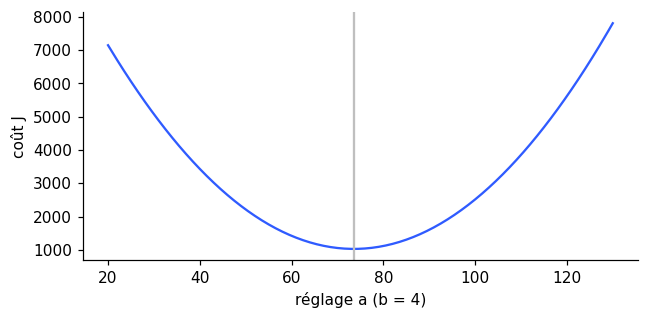

In [5]:
valeurs = np.linspace(20, 130, 221)
couts = np.array([mse(x, y, v, b) for v in valeurs])

plt.figure(figsize=(6, 3))
plt.plot(valeurs, couts, color="#2F5BFF")
plt.axvline(valeurs[couts.argmin()], color="0.75")
plt.xlabel("réglage a (b = 4)")
plt.ylabel("coût J")
plt.tight_layout()

print(f"creux vers a = {valeurs[couts.argmin()]:.1f}")
assert 73 <= valeurs[couts.argmin()] <= 75

## À vous

1. Remplacez la MSE par l'erreur absolue moyenne. Le creux change-t-il de place ?
2. Doublez l'erreur sur une seule vente : laquelle des deux mesures réagit le plus ?

**Sources** : Machine Learning Crash Course, De Cock (2011), cours BCEAO du 27 octobre 2026.